<a href="https://colab.research.google.com/github/SUCCESSneeded/practice/blob/main/Mlmaths.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
import random

In [3]:
l=[]
for i in range(10000):
  a=random.randint(1,6)
  b=random.randint(1,6)
  l.append(a+b)

In [4]:
len(l)

10000

In [5]:
l[:5]

[9, 5, 10, 4, 5]

In [6]:
s=(pd.Series(l).value_counts()/pd.Series(l).value_counts().sum()).sort_index()
print(s)

2     0.0292
3     0.0537
4     0.0845
5     0.1095
6     0.1371
7     0.1695
8     0.1384
9     0.1132
10    0.0837
11    0.0529
12    0.0283
Name: count, dtype: float64


<Axes: >

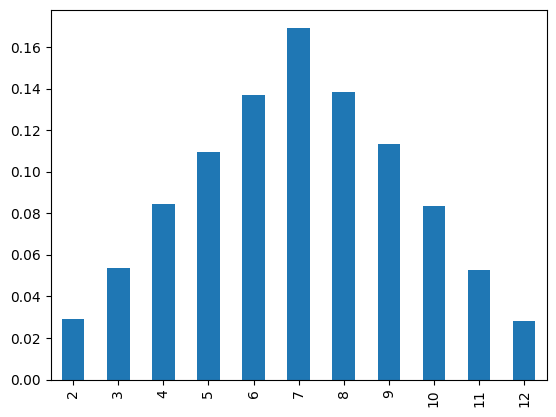

In [7]:
s.plot(kind='bar')

<Axes: >

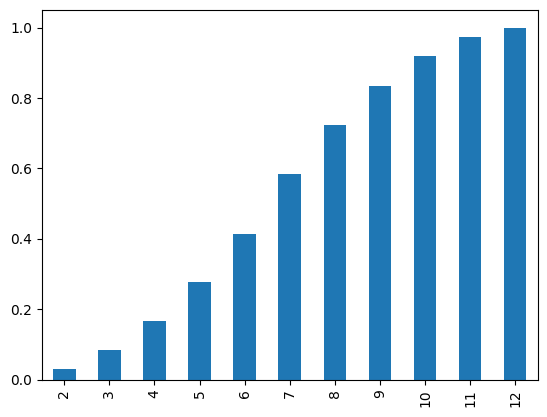

In [8]:
np.cumsum(s).plot(kind='bar')

PARAMETRIC DENSITY ESTIMATION

In [9]:
from numpy.random import normal

sample=normal(loc=50,scale=5,size=1000)
print(sample)
#loc=mean ,scale=std

[45.76794549 53.81224532 49.36221112 53.44628417 45.85997338 51.58676134
 49.75814685 53.628012   59.287604   40.60985683 54.11232166 44.93974644
 55.69722043 53.04333821 47.92404509 62.33895688 56.4358591  49.28140069
 55.68480194 49.04441001 51.35155009 44.59575923 54.31098214 48.78629547
 50.79469842 52.53988473 46.92251376 42.30757191 49.20136489 46.38952802
 50.55104942 52.46772176 50.67817152 58.69097459 55.68752746 53.23182839
 46.43741637 50.16039476 49.04823514 54.9684353  44.86696978 49.34981934
 41.07779006 53.30591803 48.03732692 41.90432343 50.77891174 51.17313054
 51.7433687  44.28536607 42.70008048 53.79356822 62.03024209 53.05619854
 55.0271874  47.0723286  48.87808215 49.64996806 56.67357317 44.81094394
 52.37120957 51.37666655 47.19410023 48.10150769 41.54500426 50.43120811
 49.91296094 53.72035151 47.09203638 53.66500211 50.37400407 43.38363949
 49.82982144 46.02382393 43.43100466 45.87107446 46.33553685 43.45639472
 47.41249819 51.05976947 42.12009128 56.48539129 57

In [10]:
sample.mean()

np.float64(49.9963870674439)

(array([  5.,  18.,  86., 174., 247., 220., 151.,  71.,  22.,   6.]),
 array([34.20385632, 37.40086668, 40.59787704, 43.79488741, 46.99189777,
        50.18890813, 53.3859185 , 56.58292886, 59.77993922, 62.97694959,
        66.17395995]),
 <BarContainer object of 10 artists>)

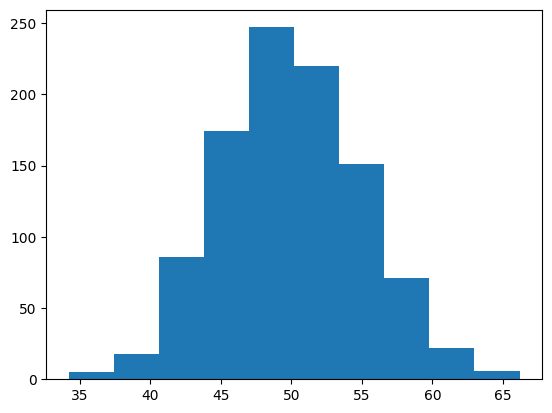

In [11]:
plt.hist(sample,bins=10)

In [12]:
sample_mean=sample.mean()
sample_std=sample.std()

In [13]:
from scipy.stats import norm
dist=norm(sample_mean,sample_std)

In [14]:
sample.min()

np.float64(34.20385631515261)

In [15]:
sample.max()

np.float64(66.17395995005276)

In [16]:
# generating 100 datapts
values=np.linspace(sample.min(),sample.max(),100)

In [17]:
probabilities=[dist.pdf(value) for value in values]

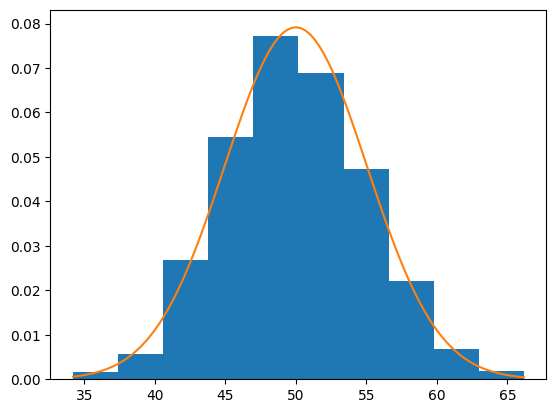

In [18]:
plt.hist(sample,bins=10,density=True)
plt.plot(values,probabilities)

/tmp/ipykernel_4240/1482356190.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(sample)


<Axes: ylabel='Density'>

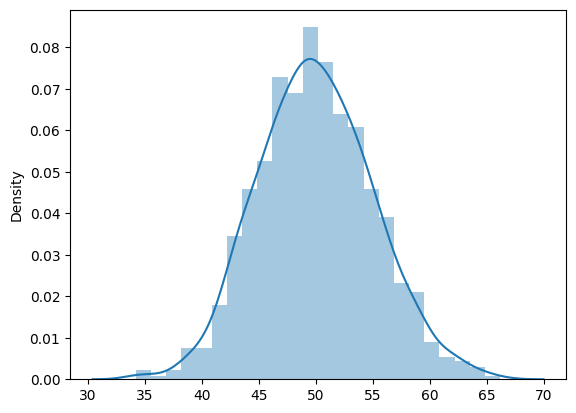

In [19]:
import seaborn as sns
sns.distplot(sample)

KDE

In [20]:
sample1=normal(loc=20,scale=5,size=300)
sample2=normal(loc=40,scale=5,size=700)
sample=np.hstack((sample1,sample2))

In [21]:
sample

array([ 9.75120017, 17.76204542, 17.1461791 , 16.93049499, 24.53638132,
       21.82194626, 18.29113549,  9.16344681, 17.77720765, 12.05467279,
       20.78060716, 25.48999659, 26.5208378 , 18.27600784, 18.99309675,
       17.29187352, 22.41680993, 21.03182766, 19.56023357, 16.68770402,
       28.94080661, 19.77925928, 20.56001365, 20.72888727, 25.24900773,
       11.94264276, 20.88856257, 17.45075099, 21.52790915, 19.19135571,
       12.82664914, 21.98024589, 16.52249431, 15.45219952, 25.90147436,
       19.41598228, 21.35564297, 26.33936701, 23.90671099, 21.85591546,
       12.93688839, 21.20597397, 15.60011279, 26.19883405, 24.14774066,
       18.30908754, 15.16885507, 24.36561663, 18.04996792, 18.51788686,
       20.11296117, 15.21848713,  9.14864746, 21.91523247, 26.49934442,
       22.57656458, 23.55497986, 19.01802435, 16.95994513, 31.39632812,
        9.67189084, 12.99748656, 26.07190562, 17.66998123, 21.49824374,
       10.61266601, 27.50078018, 18.929837  , 16.99277002, 23.16

(array([ 2.,  0.,  1.,  5.,  5.,  7., 12.,  6.,  9., 17., 22., 25., 26.,
        25., 14., 21., 26., 18., 17.,  8., 14., 10., 10., 10., 12., 28.,
        16., 34., 36., 41., 56., 54., 55., 39., 49., 49., 46., 47., 40.,
        21., 21., 15., 11.,  8.,  4.,  4.,  2.,  1.,  0.,  1.]),
 array([ 5.33194859,  6.35975524,  7.38756188,  8.41536852,  9.44317516,
        10.47098181, 11.49878845, 12.52659509, 13.55440173, 14.58220837,
        15.61001502, 16.63782166, 17.6656283 , 18.69343494, 19.72124159,
        20.74904823, 21.77685487, 22.80466151, 23.83246816, 24.8602748 ,
        25.88808144, 26.91588808, 27.94369472, 28.97150137, 29.99930801,
        31.02711465, 32.05492129, 33.08272794, 34.11053458, 35.13834122,
        36.16614786, 37.19395451, 38.22176115, 39.24956779, 40.27737443,
        41.30518107, 42.33298772, 43.36079436, 44.388601  , 45.41640764,
        46.44421429, 47.47202093, 48.49982757, 49.52763421, 50.55544086,
        51.5832475 , 52.61105414, 53.63886078, 54.66666742,

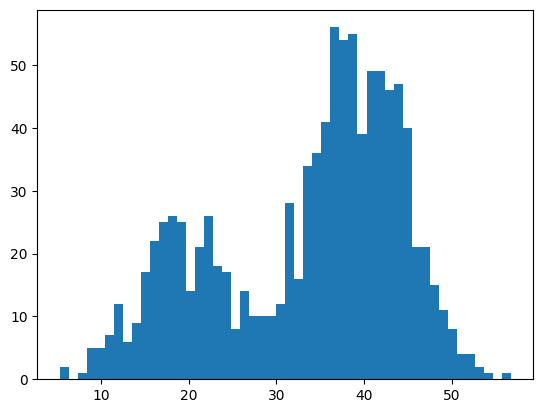

In [22]:
plt.hist(sample,bins=50)

In [23]:
from sklearn.neighbors import KernelDensity

model=KernelDensity(kernel='gaussian',bandwidth=3)
#model.fit(sample)

How to use PDF in data science

In [24]:
dataset=sns.load_dataset("iris")

In [25]:
dataset.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


<Axes: xlabel='sepal_length', ylabel='Density'>

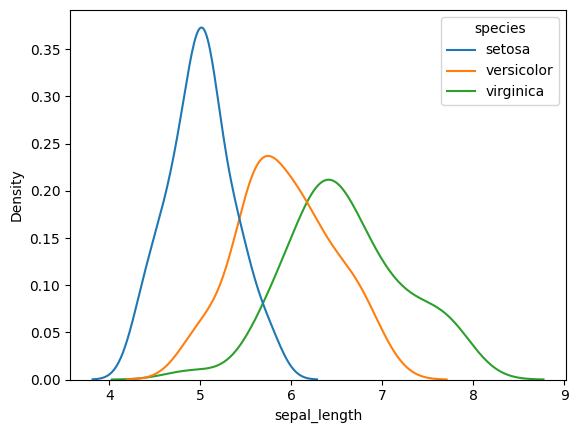

In [26]:
sns.kdeplot(data=dataset,x="sepal_length",hue=dataset["species"])

<Axes: xlabel='sepal_width', ylabel='Density'>

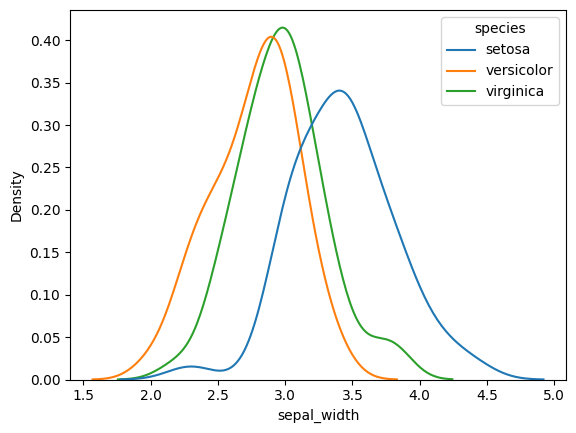

In [27]:
sns.kdeplot(data=dataset,x="sepal_width",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

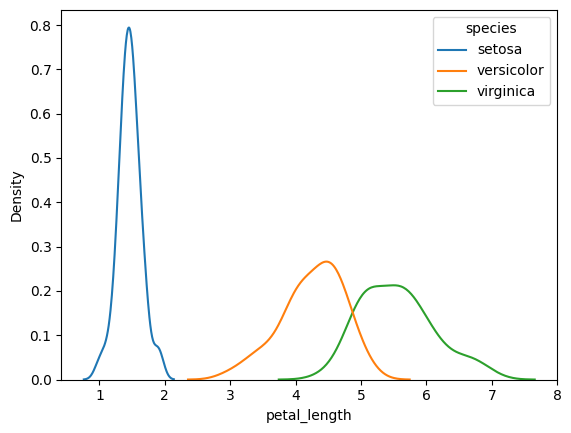

In [28]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

<Axes: xlabel='petal_length', ylabel='Density'>

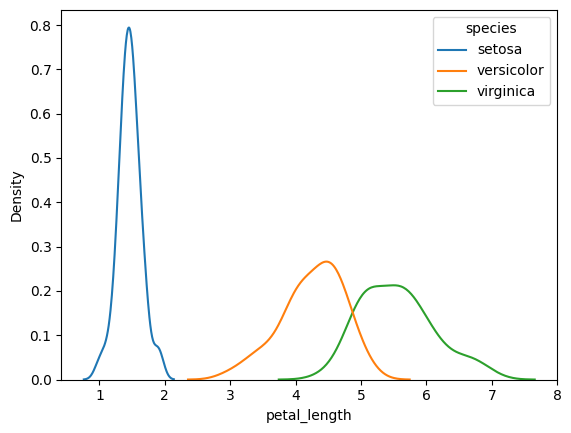

In [29]:
sns.kdeplot(data=dataset,x="petal_length",hue=dataset["species"])

In [30]:
tips=sns.load_dataset("tips")

In [31]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='tip', ylabel='Density'>

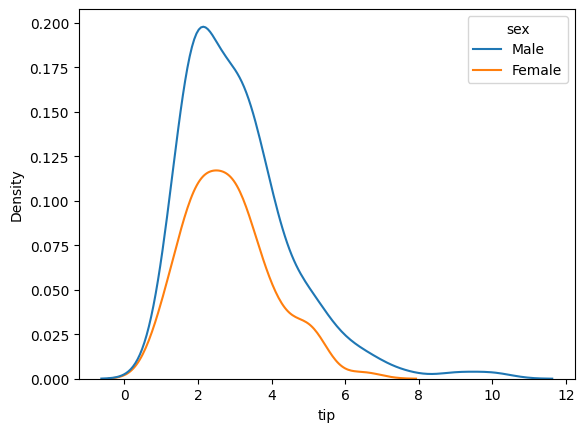

In [32]:
sns.kdeplot(data=tips,x="tip",hue="sex")

<Axes: xlabel='petal_width', ylabel='Density'>

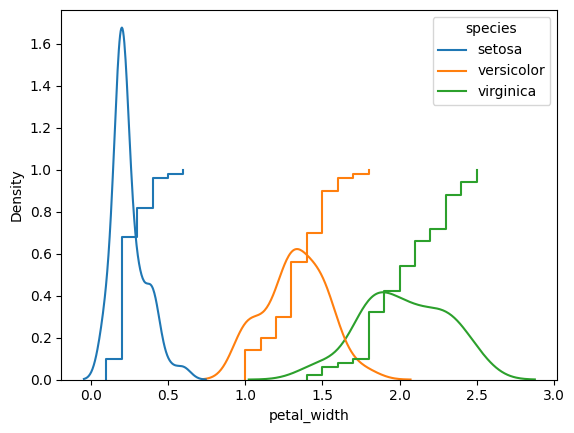

In [33]:
sns.kdeplot(data=dataset,x="petal_width",hue=dataset["species"])
sns.ecdfplot(data=dataset,x="petal_width",hue=dataset["species"])

2D density plots

In [34]:
#contour plots

How to find distribution is normal or not?

In [35]:
iris=sns.load_dataset("iris")

<Axes: xlabel='sepal_length', ylabel='Density'>

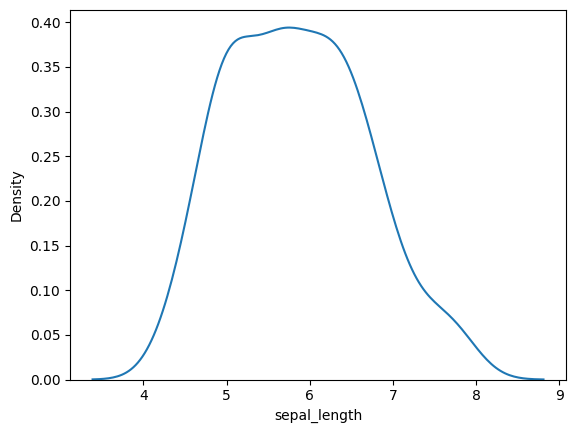

In [36]:
sns.kdeplot(iris["sepal_length"])

In [37]:
temp=sorted(iris['sepal_length'].tolist())

In [38]:
y_quant=[]

for i in range(1,101):
  y_quant.append(np.percentile(temp,i))

In [39]:
samples=np.random.normal(loc=0,scale=1,size=1000)

In [40]:
x_quant=[]

for i in range(1,101):
  x_quant.append(np.percentile(samples,i))

<Axes: >

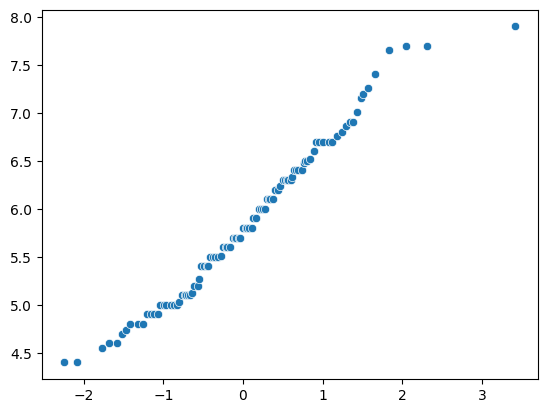

In [41]:
sns.scatterplot(x=x_quant,y=y_quant)

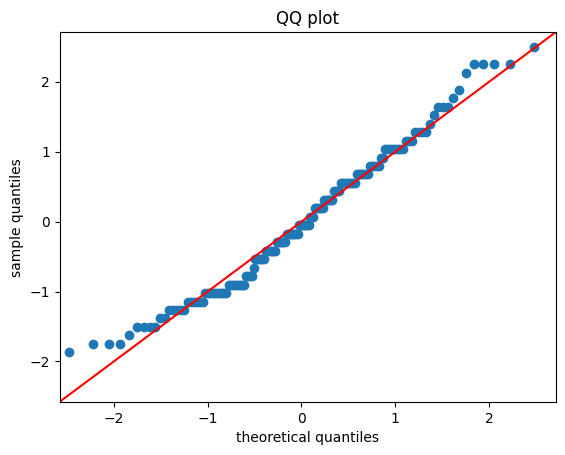

In [42]:
#using statsmodel

import statsmodels.api as sm

#create QQplot of two sets of data
fig=sm.qqplot(iris['sepal_length'],line='45',fit=True)

plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [43]:
import scipy.stats as stats

In [44]:
#genertate a set of random data
x=np.random.uniform(low=0,high=1,size=1000)

(array([ 98.,  97.,  87., 123.,  98., 108.,  94.,  94., 104.,  97.]),
 array([8.30979696e-04, 1.00743819e-01, 2.00656659e-01, 3.00569498e-01,
        4.00482338e-01, 5.00395177e-01, 6.00308017e-01, 7.00220856e-01,
        8.00133696e-01, 9.00046535e-01, 9.99959375e-01]),
 <BarContainer object of 10 artists>)

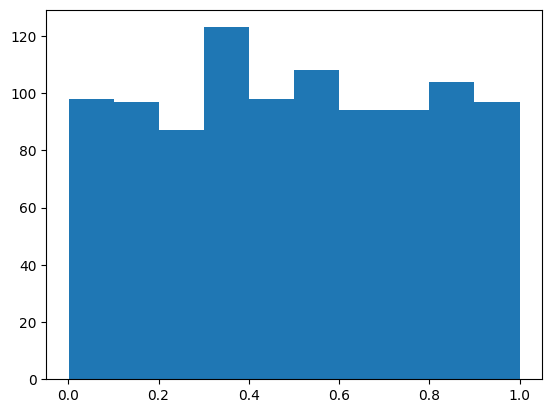

In [45]:
plt.hist(x)

PARETO DISTRIBUTION

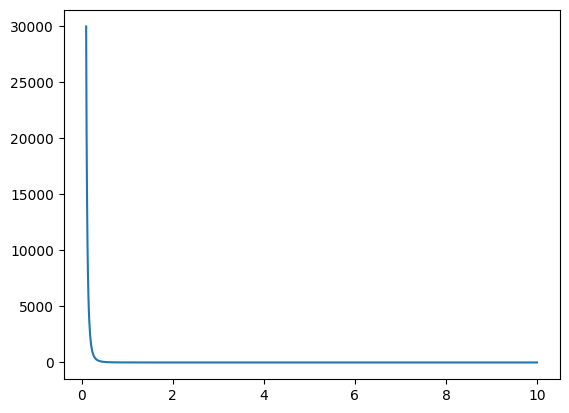

In [46]:
# DEFINE PARAMETERS OF Pareto distribution

alpha=3
xm=1

# create an array of x variables
x=np.linspace(0.1,10,1000)

#calculate teh y values of the pareto distribution
y=alpha*(xm**alpha)/(x**(alpha+1))

plt.plot(x,y)

Text(0.5, 1.0, 'Pareto distribution')

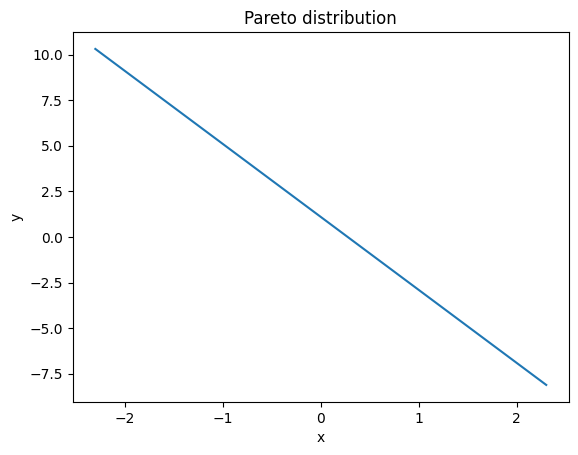

In [47]:
#calculate the log-log plot
plt.plot(np.log(x),np.log(y))
plt.xlabel("x")
plt.ylabel("y")
plt.title("Pareto distribution")

In [48]:
alpha =2
xm=1

x=stats.pareto.rvs(b=alpha,scale=xm,size=1000)

(array([976.,  13.,   7.,   0.,   1.,   0.,   0.,   1.,   0.,   2.]),
 array([ 1.00012479,  5.59758369, 10.19504258, 14.79250147, 19.38996037,
        23.98741926, 28.58487815, 33.18233705, 37.77979594, 42.37725483,
        46.97471373]),
 <BarContainer object of 10 artists>)

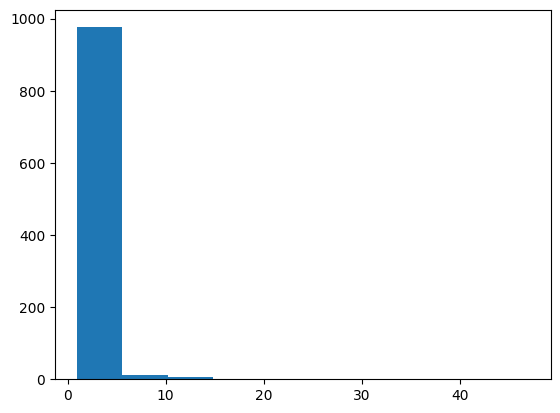

In [49]:
plt.hist(x)

In [50]:
params=stats.pareto.fit(x,floc=0)

#create a pareto distribution object with the fitted parameters
dist=stats.pareto(b=params[0],scale=params[2])

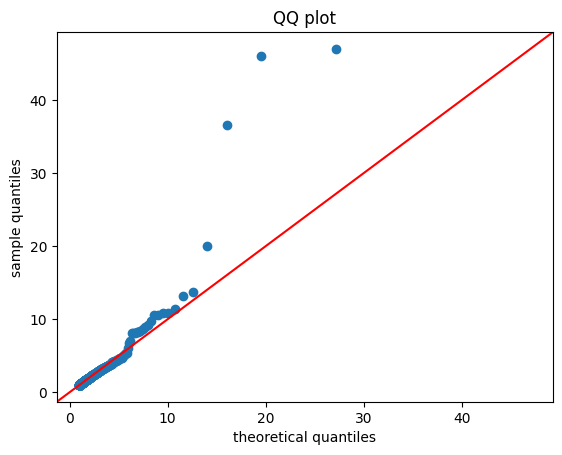

In [51]:
fig=sm.qqplot(x,line='45',dist=dist)
plt.title("QQ plot")
plt.xlabel("theoretical quantiles")
plt.ylabel("sample quantiles")
plt.show()

In [52]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url,usecols=['Battery Age','Cycle Count','Daily Usage Hours'])
battery_csv=df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [53]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [54]:
from scipy.stats import stats
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

In [55]:
df.isnull().sum()
# if missing values use df['column'].fillna(df['column'].mean(),inplace=True)

,0
Battery Age,0
Daily Usage Hours,0
Gaming User,0
Design Capacity,0
Cycle Count,0
CPU Usage,0
GPU Usage,0
Power Consumption,0
Average Temperature,0
Full Charge Capacity,0


In [56]:
x=df.iloc[:,1:5]
y=df.iloc[:,0]

In [57]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

/tmp/ipykernel_4240/1170598051.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_train['Daily Usage Hours'])


Text(0.5, 1.0, 'Daily Usage Hours QQ plot')

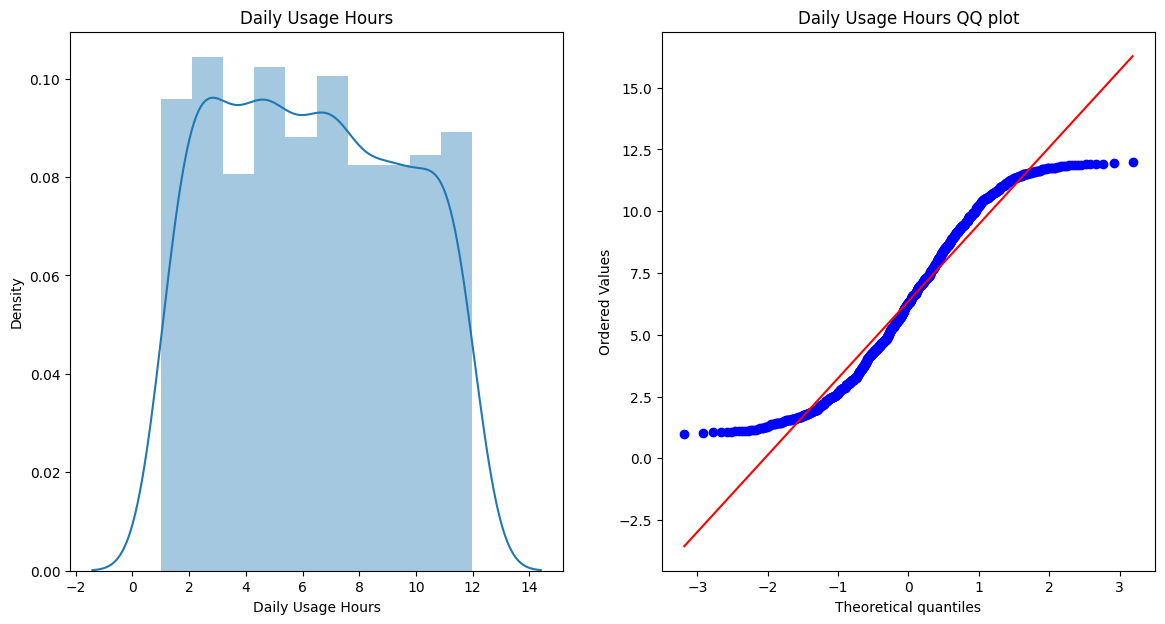

In [58]:
import scipy.stats as stats

plt.figure(figsize=(14,7))
plt.subplot(121)
sns.distplot(x_train['Daily Usage Hours'])
plt.title("Daily Usage Hours")
plt.subplot(122)
stats.probplot(x_train['Daily Usage Hours'],dist="norm",plot=plt)
plt.title("Daily Usage Hours QQ plot")

Text(0.5, 1.0, 'Cycle Count QQ plot')

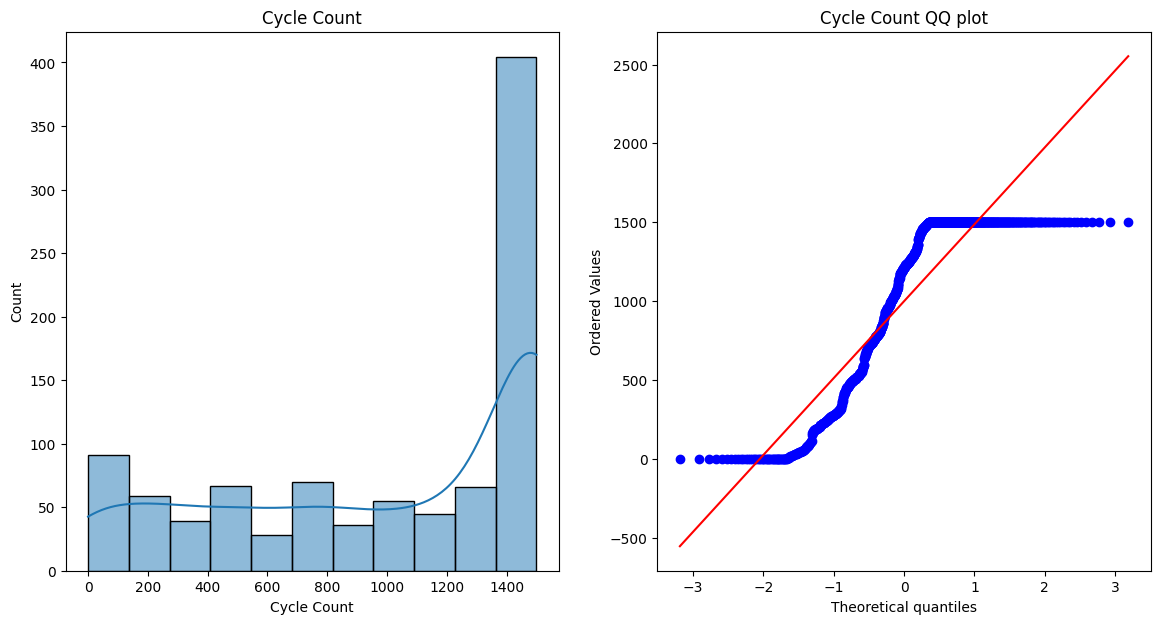

In [59]:
plt.figure(figsize=(14,7))
plt.subplot(121)
sns.histplot(x_train['Cycle Count'], kde=True)
plt.title("Cycle Count")
plt.subplot(122)
stats.probplot(x_train['Cycle Count'],dist="norm",plot=plt)
plt.title("Cycle Count QQ plot")

In [60]:
clf1=LogisticRegression()
clf2=DecisionTreeClassifier()

In [61]:
print(y.value_counts())
print(x.shape, y.shape)

Battery Age
5    145
3    134
9    130
7    126
6    123
0    113
2    112
1    109
4    107
8    101
Name: count, dtype: int64
(1200, 4) (1200,)


In [62]:
print(x.head())
print(y.head())
print(x.nunique())

   Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
0           9.797617            0            57884         1267
1           7.101557            0            63824         1500
2          10.085255            0            79414         1500
3           7.946047            0            61142         1153
4           9.628460            0            50956         1500
0    5
1    9
2    9
3    5
4    7
Name: Battery Age, dtype: int64
Daily Usage Hours    1200
Gaming User             2
Design Capacity      1175
Cycle Count           562
dtype: int64


In [63]:
df.corr(numeric_only=True)['Battery Age']

,Battery Age
Battery Age,1.000000
Daily Usage Hours,0.058817
Gaming User,-0.029423
Design Capacity,-0.005563
Cycle Count,0.952206
CPU Usage,0.026371
GPU Usage,0.016243
Power Consumption,0.020669
Average Temperature,0.017784
Full Charge Capacity,-0.472370


In [64]:
clf1.fit(x_train,y_train)
clf2.fit(x_train,y_train)

y_pred=clf1.predict(x_test)
y_pred2=clf2.predict(x_test)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.5041666666666667
Accuracy DT 0.775


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [65]:
trf=FunctionTransformer(np.log1p)

In [66]:
x_train_transform=trf.fit_transform(x_train)
x_test_transform=trf.transform(x_test)

print(x_train_transform)
print(x_test_transform)

      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
1055           2.536398     0.000000        11.080988     7.313887
1033           1.530651     0.000000        11.222119     7.312553
783            2.431201     0.000000        10.775576     7.313887
998            2.531171     0.000000        11.060290     7.313887
351            2.026217     0.000000        10.940508     5.231109
...                 ...          ...              ...          ...
693            2.497217     0.000000        10.963913     0.000000
485            2.315912     0.000000        11.239054     7.279319
261            1.389027     0.693147        10.787565     0.000000
616            1.650776     0.000000        10.810051     6.224558
1086           2.245548     0.000000        10.726061     0.000000

[960 rows x 4 columns]
      Daily Usage Hours  Gaming User  Design Capacity  Cycle Count
103            2.306535          0.0        11.237146     5.720312
759            1.154633          0.0  

In [67]:
clf=LogisticRegression()
clf2=DecisionTreeClassifier()

clf.fit(x_train_transform,y_train)
clf2.fit(x_train_transform,y_train)

y_pred=clf.predict(x_test_transform)
y_pred2=clf2.predict(x_test_transform)

print("Accuracy LR",accuracy_score(y_test,y_pred))
print("Accuracy DT",accuracy_score(y_test,y_pred2))

Accuracy LR 0.525
Accuracy DT 0.7666666666666667


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PDF of binomial ditribution.

[ 3  6  7  6  3  5  6  9  8  8  4  4  6  4  6  3  6  5  4  5  5  4  3  4
  7  6  6  5  5  3  7  6  5  6  9  5  6  3  4  4  4  6  4  8  4  5  7  2
  6  5  8  4  5  5  2  7  4  4  2  4  3  4  4  5  3  5  6  4  7  4  6  7
  3  3  7  7  2  4  7  5  6  5  6  4  6  6  5  6  5  2  5  7  2  5  8  4
  7  5  6  7  6  3  4  6  5  6  5  4  4  4  3  5  4  3  6  6  5  3  7  5
  3  4  6  5  6  5  4  4  3  3  8  5  6  6  6  2  6  6  4  4  5  5  2  5
  6  4  6  6  3  4  6  8  8  5  4  7  1  7  4  3  6  4  9  5  6  5  6  2
  4  5  5  4  4  7  6  6  5  6  5  5  6  4  5  5  5  5  6  4  4  6  7  3
  5  3  6  6  5  6  4  7  4  4  6  7  2  5  4  4  4  2  6  6  4  4  5  2
  3  3  6  5  5  6  4  4  6  6  5  2  5  6  0  5  6  7  4  4  2  5  4  7
  2  6  1  6  6  3  3  7  5  5  8  6  2  2  3  5  5  4  7  7  8  3  6  3
  6  4  4  3  4  8  7  3  5  7  8  6  4  5  5  1  3  8  5  6  7  5  4  3
  7  4  5  4  6  3  2  4  3  2  3  6  2  5  6  3  4  4  5  5  3  5  7  4
  1  4  7  5  2  1  4  6  3  7  6  5  7  6  3  6  4

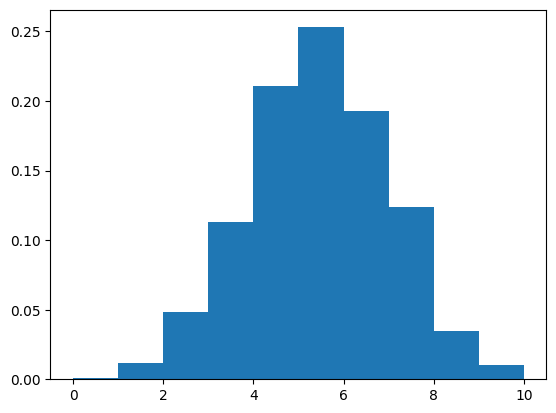

In [68]:
n=10    #number of trials
probability=0.5
binomial_d=np.random.binomial(n=n,p=probability,size=1000)
print(binomial_d)
plt.hist(binomial_d,density=True)
plt.show()
# when probability of success is less left skewed graph and vice versa

Central limit theorem

In [69]:
num_sample=100000
sample_size=300
dist_range=(0,1)

samples=np.random.uniform(dist_range[0],dist_range[1],(num_sample,sample_size))
samples.shape

(100000, 300)

In [70]:
sample_mean=np.mean(samples,axis=1)
sample_mean

array([0.49079209, 0.48998905, 0.51297991, ..., 0.48958843, 0.51239692,
       0.5062459 ])

In [71]:
sample_mean.shape

(100000,)

Text(0.5, 1.0, 'histogram of sample means')

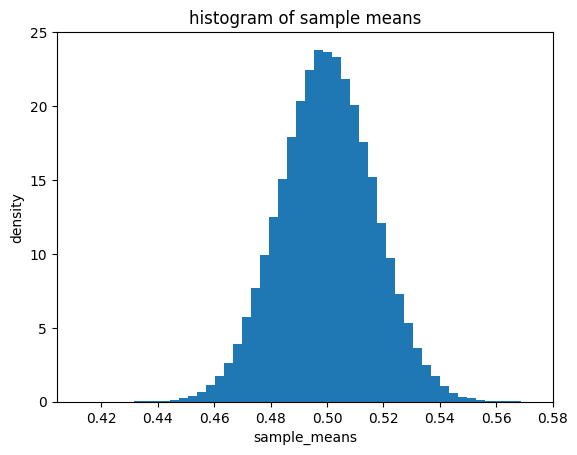

In [72]:
plt.hist(sample_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of sample means")

# greater the number of samples ,gratere is the chances of normal distribution

Different different distributions.

In [73]:
sample_nums=10000
sample_size=50

#poisson distribution parameters
poisson_lambda=5

#gamma distribution parameters
gamma_shape=2
gamma_scale=1

#binomial distribution parameters
binomial_n=10
binomial_p=0.5

# generation
poisson_d=np.random.poisson(lam=poisson_lambda,size=(sample_nums,sample_size))
gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(sample_nums,sample_size))
binomial_d=np.random.binomial(n=binomial_n,p=binomial_p,size=(sample_nums,sample_size))

#calculate means
poisson_mean=np.mean(poisson_d,axis=1)
gamma_mean=np.mean(gamma_d,axis=1)
binomial_mean=np.mean(binomial_d,axis=1)


Text(0.5, 1.0, 'histogram of biomial means')

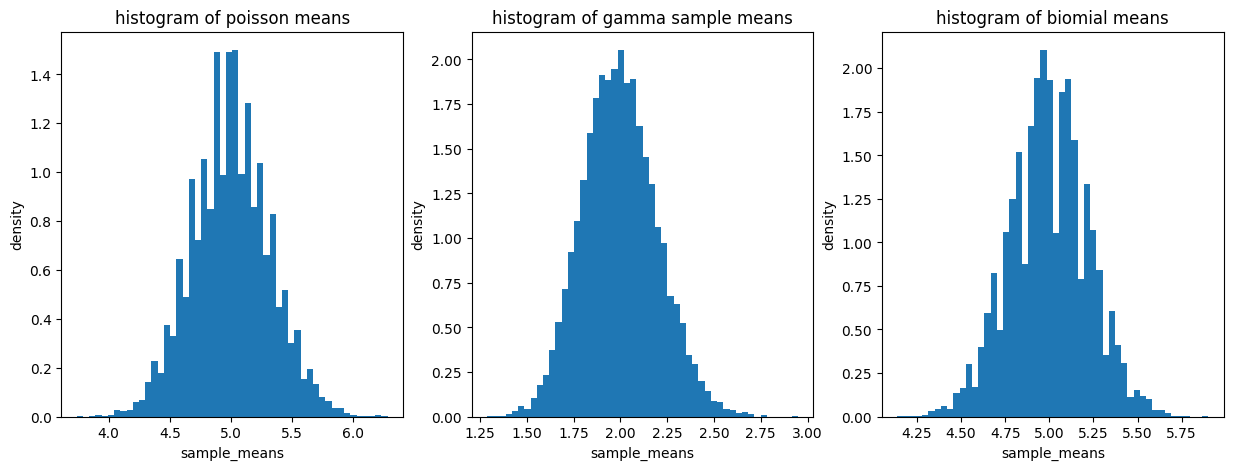

In [74]:
plt.figure(figsize=(15,5))
plt.subplot(1,3,1,)
plt.hist(poisson_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of poisson means")

plt.subplot(1,3,2)
plt.hist(gamma_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of gamma sample means")

plt.subplot(1,3,3)
plt.hist(binomial_mean,density=True,bins=50)
plt.xlabel("sample_means")
plt.ylabel("density")
plt.title("histogram of biomial means")

In [75]:
gamma_samples=1000
gamma_size=30

gamma_shape=2
gamma_scale=1

theorotical_mean=gamma_shape*gamma_scale
theorotical_var=(gamma_shape*gamma_scale**2)

gamma_d=np.random.gamma(shape=gamma_shape,scale=gamma_scale,size=(gamma_samples,gamma_size))

gamma_means=np.mean(gamma_d,axis=1)
emperical_mean=np.mean(gamma_means)
emperical_var=np.var(gamma_means)

print("Theorotical mean:",theorotical_mean)
print("Theorotical variance:",theorotical_var)
print("Emperical mean:",emperical_mean)
print("Emperical variance:",emperical_var)


Theorotical mean: 2
Theorotical variance: 2
Emperical mean: 1.9932688836908823
Emperical variance: 0.06388274059055511


CASE STUDY

In [76]:
battery_csv.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [77]:
battery_csv.shape

(1200, 11)

In [78]:
d=battery_csv.sample(1200)
d

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
809,3,4.310630,1,61450,692,62.499318,67.485787,96.076255,31.186885,53509.240027,83.061247
964,5,4.693980,0,63055,1227,35.557118,29.956395,44.161161,30.531905,50392.887464,80.592165
288,2,2.510300,0,56161,516,26.929235,18.446340,48.230705,32.189363,51314.493296,90.828891
131,5,4.935924,0,58358,1281,47.905189,40.064737,53.002515,26.631536,45543.858489,75.320563
563,7,7.013450,1,46597,1500,82.831169,77.987791,105.656200,35.626366,31446.809274,66.449273
...,...,...,...,...,...,...,...,...,...,...,...
428,5,4.710637,0,60082,1239,29.268075,21.164726,41.147366,23.435320,48883.063044,78.745664
1035,9,6.549532,1,67465,1500,79.643537,65.948037,73.837774,29.878261,49520.951788,75.313537
40,4,11.557701,0,56139,1072,74.180969,48.285570,78.031924,33.677576,45859.617078,82.255689
889,3,1.080883,0,54399,807,19.996594,16.785370,36.906625,28.836429,46508.431040,86.439701


In [79]:
d['Daily Usage Hours'].mean()

np.float64(6.435078131250979)

<Axes: ylabel='Density'>

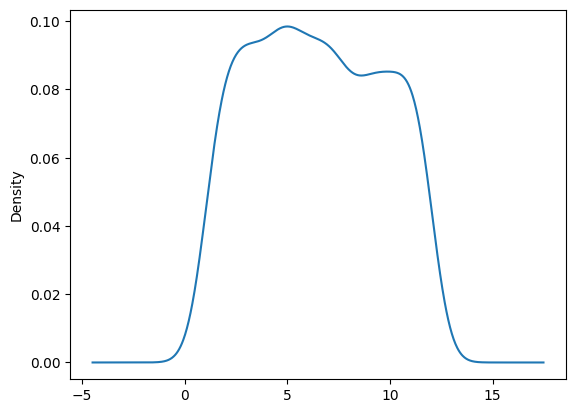

In [80]:
d['Daily Usage Hours'].plot(kind='density')

In [81]:
# taking out 50 samples
df['Daily Usage Hours'].sample(50)

,Daily Usage Hours
296,10.443571
689,5.177111
1133,4.345041
319,8.803277
865,3.406489
7,11.537404
119,5.356011
1170,9.887531
1152,7.262355
274,10.429540


In [82]:
# converting into pyhton list
df['Daily Usage Hours'].sample(50).values.tolist()

[9.772654498261344,
 11.279982687870673,
 10.515782093129332,
 7.331527715040902,
 6.628781918261709,
 4.031234539400963,
 10.281941500241366,
 6.641622165357945,
 11.884558667227546,
 6.188144398256549,
 6.521399456450259,
 4.137263829484555,
 2.199149772050216,
 7.139883022794848,
 9.49367230377422,
 1.7827124676570072,
 5.909589959852173,
 9.134161565626,
 2.97080310119166,
 8.430016498700681,
 7.690325144430913,
 7.8571752255589775,
 3.1900276192951824,
 9.273257659666722,
 8.612556083437193,
 7.584192925395359,
 7.938474621898827,
 1.6007133353481595,
 7.627160875029931,
 10.63495417499884,
 3.4712313740594327,
 4.9395368818205885,
 5.329108697169471,
 11.003724540544642,
 8.454955653214526,
 3.1849477524805603,
 10.033751700156747,
 1.5456649918443102,
 11.127605408564817,
 7.101557272672039,
 4.826045821763506,
 8.070551548279207,
 4.9928112444425885,
 2.5531896989090344,
 11.60053707555754,
 9.826419628964569,
 5.8933767611029495,
 8.783826443145887,
 6.597834770768682,
 6.8100

In [83]:
samples=[]
for i in range(100):
  samples.append(df['Daily Usage Hours'].sample(50).values.tolist())

In [84]:
samples

[[5.628102188254784,
  4.11612843841835,
  6.698852478443793,
  2.159415151361085,
  3.95677376533218,
  2.362306293763992,
  9.400614962853526,
  3.3000710104857567,
  4.065637475213784,
  6.3184789361748415,
  9.580528957440478,
  4.199645396547408,
  10.3230239636021,
  7.106471654285073,
  7.353743887008471,
  9.064764159504795,
  5.458578967116487,
  2.2084942511486125,
  9.003942514696575,
  6.549015358362909,
  3.960777280907921,
  6.230232867560071,
  2.797034342382622,
  10.515782093129332,
  8.470788251515192,
  1.9873545061617284,
  9.134161565626,
  3.306593051732209,
  4.349394667894334,
  10.75018398156156,
  2.3343329780608757,
  6.322462407507426,
  1.6007133353481595,
  8.0707457755694,
  6.0698817202724005,
  3.733938030201686,
  5.711869806257309,
  11.339168101742798,
  6.622250023384506,
  2.4661268389039046,
  9.772654498261344,
  2.807155275996502,
  1.0460618799075363,
  11.741021823789511,
  9.785213583923,
  3.033222377417274,
  9.41116045423361,
  2.570957349

In [85]:
samples=np.array(samples)
samples

array([[ 5.62810219,  4.11612844,  6.69885248, ...,  2.57095735,
         7.20858247,  8.78382644],
       [ 4.55090773,  7.8866018 ,  5.2677003 , ..., 11.47625428,
         6.91294158,  9.08527705],
       [ 1.26405549,  7.64795252,  3.24470827, ...,  1.27719004,
        10.50802893,  3.32920448],
       ...,
       [10.47831373,  6.70622632,  7.21957534, ...,  1.60462938,
         8.13621825,  5.76123913],
       [ 2.34747648,  1.93943333,  7.71399309, ...,  1.74841046,
         8.90589925,  7.57043616],
       [ 1.63131028,  9.45967246,  7.76962858, ...,  2.94790481,
         7.70794038,  2.25362476]])

In [86]:
# calculate mean for each row
sampling_means=samples.mean(axis=1)

In [87]:
sampling_means.mean()

np.float64(6.4251253705047375)

In [88]:
sampling_means.std()/np.sqrt(50)

np.float64(0.06241268952471693)

<Axes: ylabel='Density'>

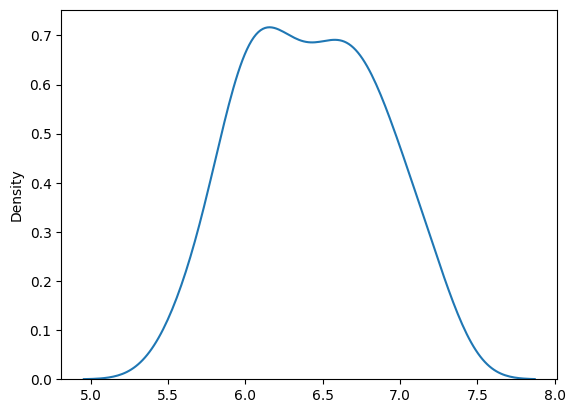

In [89]:
sns.kdeplot(data=sampling_means)

In [90]:
lower_limit=sampling_means.mean()-2*sampling_means.std()/np.sqrt(50)
upper_limit=sampling_means.mean()+2*sampling_means.std()/np.sqrt(50)

print("the range is:",lower_limit,"-",upper_limit)

the range is: 6.3002999914553035 - 6.549950749554172


t-test

In [91]:
url="https://raw.githubusercontent.com/SUCCESSneeded/numpy-100/refs/heads/master/battery_health_dataset.csv"
df=pd.read_csv(url)
df.head()

,Battery Age,Daily Usage Hours,Gaming User,Design Capacity,Cycle Count,CPU Usage,GPU Usage,Power Consumption,Average Temperature,Full Charge Capacity,Battery Health
0,5,9.797617,0,57884,1267,64.587764,43.887115,84.366245,35.645636,44961.935220,76.923383
1,9,7.101557,0,63824,1500,45.542182,36.534144,80.629042,31.782432,46619.665590,73.496153
2,9,10.085255,0,79414,1500,64.640516,52.238349,87.853504,32.122879,63343.419989,81.514041
3,5,7.946047,0,61142,1153,55.095724,30.535647,69.686012,30.371133,50407.438833,79.742100
4,7,9.628460,0,50956,1500,60.145756,36.749489,64.734123,27.536232,34757.377982,67.882552


In [92]:
train=df.drop(columns=['Battery Health'])
test=df['Battery Health']

In [93]:
final=pd.concat([train,test]).sample(1000)

In [94]:
corr = df.corr(numeric_only=True)['Battery Health'].drop(
    'Battery Health'
)
print(corr)

Battery Age            -0.900723
Daily Usage Hours      -0.084347
Gaming User             0.018509
Design Capacity         0.289450
Cycle Count            -0.921454
CPU Usage              -0.052363
GPU Usage              -0.033122
Power Consumption      -0.048988
Average Temperature    -0.041134
Full Charge Capacity    0.704030
Name: Battery Health, dtype: float64


In [95]:
meanf=np.mean(df['Full Charge Capacity'])
print(meanf)

51798.12594357623


In [96]:
#H_0:u=51798.13
#H_a:u!=51798.13

In [97]:
vals=final['Full Charge Capacity'].dropna()

In [98]:
sample_vals=vals.sample(200).values
sample_vals

array([36221.94777185, 61482.14391704, 45905.0310915 , 44475.80746904,
       71227.17782884, 46813.10130119, 52836.97110178, 45736.70302765,
       37147.49450584, 47503.86958053, 45348.09792601, 47912.46385087,
       57694.75208935, 31514.74874821, 54949.90496207, 64331.64719944,
       50145.68970628, 35196.1337385 , 56593.01855858, 41274.04174681,
       54475.80100796, 63737.54957258, 62728.81813405, 30935.86599096,
       58366.31649895, 71742.43891365, 47354.28235363, 76179.57877402,
       52289.59826314, 31502.86939656, 32881.98754535, 61375.56387158,
       40136.86876174, 53754.56366273, 47810.42688472, 64867.49325256,
       62235.6495512 , 48528.76377835, 61978.10689629, 49357.69111636,
       45281.02541589, 37777.23708547, 56359.51728863, 41654.67000562,
       58212.55908929, 55672.26742603, 41878.21504094, 59635.43126105,
       52223.22113422, 51950.41274877, 59213.7104511 , 57191.87392455,
       68556.57145802, 28695.87567242, 55948.28855426, 32467.01091439,
      

In [99]:
mean_s=np.mean(sample_vals)
print(mean_s)
std_s=np.std(sample_vals)
print(std_s)

52191.67621293774
11458.825031145672


In [100]:
#check normality using shapiro wilk test
from scipy.stats import shapiro

shapiro_s=shapiro(sample_vals)
print(shapiro_s)

ShapiroResult(statistic=np.float64(0.9833352792821022), pvalue=np.float64(0.018065240936756124))


In [101]:
import scipy.stats as stats

t_statistics,p_value=stats.ttest_1samp(sample_vals,50000)
print(t_statistics,p_value/2)


2.6981298348470806 0.003785970872070146


INDEPENDENT 2SAMPLE T-TEST

In [103]:
url="https://raw.githubusercontent.com/SUCCESSneeded/practice/refs/heads/main/E%20Commerce%20Dataset%20(1).csv"
df2=pd.read_csv(url)
print(df2.head())
df2.shape

HTTPError: HTTP Error 404: Not Found

In [ ]:
churn=df2.dropna()
print(churn.head())
churn.shape

In [ ]:
churn.head()

In [ ]:
corr = df2.corr(numeric_only=True)['CashbackAmount'].drop(
    'CashbackAmount'
)
print(corr)

In [ ]:
mobile_df = churn[
    churn["PreferedOrderCat"].str.contains(
        "Phone", case=False, na=False
    )
].copy()

# Dataset for computers and laptops
computer_df = churn[
    churn["PreferedOrderCat"].str.contains(
        "Laptop|Computer", case=False, na=False, regex=True
    )
].copy()

print("Mobile dataset:", mobile_df.shape)
print("Computer dataset:", computer_df.shape)
print(mobile_df)

In [ ]:
mobile_sample=mobile_df.sample(100)
computer_sample=computer_df.sample(100)

print(mobile_sample.shape)
print(computer_sample.shape)

In [ ]:
plt.hist(mobile_sample['CashbackAmount'])

In [ ]:
mobile_smean=np.mean(mobile_sample['CashbackAmount'])
mobile_sstd=np.std(mobile_sample['SatisfactionScore'])

computer_smean=np.mean(computer_sample['CashbackAmount'])
computer_sstd=np.std(computer_sample['CashbackAmount'])
print(mobile_smean,mobile_sstd)
print(computer_smean,computer_sstd)

In [ ]:
from sklearn.preprocessing import PowerTransformer
from scipy.stats import shapiro

# Create transformer
pt = PowerTransformer(method='yeo-johnson', standardize=True)
# Transform mobile sample
mobile_sample['CashbackAmount_normal'] = pt.fit_transform(
    mobile_sample[['CashbackAmount']]
)

# Transform computer sample using its own fitted transformer
pt2 = PowerTransformer(method='yeo-johnson', standardize=True)

computer_sample['CashbackAmount_normal'] = pt2.fit_transform(
    computer_sample[['CashbackAmount']]
)

print("Mobile:", shapiro(mobile_sample['CashbackAmount_normal']))
print("Computer:", shapiro(computer_sample['CashbackAmount_normal']))

In [ ]:
sns.histplot(mobile_sample["CashbackAmount"], discrete=True)
plt.title("Mobile Users:CashbackAmount")
plt.show()

sns.histplot(computer_sample["CashbackAmount"], discrete=True)
plt.title("Computer Users: CashbackAmount")
plt.show()

In [ ]:
from scipy.stats import levene

l_test=levene(mobile_sample['CashbackAmount'],computer_sample['CashbackAmount'])
print(l_test)
'''pvalue > 0.05 therefor popvarP==popvarC'''

In [ ]:
from scipy.stats import t
t_val=6.31
dof=198
cdf_val=t.cdf(t_val,dof)
print(cdf_val*2)